# W2 · From Exploratory Analysis to Credible Validation

**Business Intelligence · IIB423T-1 · Universidad del Desarrollo**
**Group 01 · Alessandro Lavezzi · José Saavedra**

**Project.** This project studies persistent overtime among fixed-term (*a contrata*) staff of six Santiago Metropolitan Health Services (Central, North, East, West, South and South-East), September 2024 – August 2026, using the monthly payroll files that each service publishes on Chile's Transparency Portal. The KPI is the *persistence rate*: the share of people with at least 12 months in the payroll who received overtime in at least 75% of their months. The unit of observation is the person-month, and a person is identified by (service, full name) because the payroll has no national ID. This notebook extends the C1 analysis (one service) to six services and adds the validation work required by W2: data checks, sampling, leakage and a person-level holdout design.

### How to run
1. Restart the kernel and run all cells (`Kernel → Restart & Run All`). Run time is a few minutes.
2. Input: monthly CSV files in `../Data/` (paths are relative to `notebooks/`).
3. Output: figures are written to `../figures/` (created if missing). Nothing is written to `Data/`.
4. Randomness: a single `SEED = 42` is defined in the setup cell and used for the holdout split and any sampling.
5. To add a service, copy its CSV files into `Data/` with the service prefix (for example `Sur_TransparenciaActiva_YYYY-MM.csv`), add its pattern to `SERVICIOS` and rerun. Services without files are skipped.

### Sections and mapping to the W2 brief

| Section | Content | Brief part (rubric) |
|---|---|---|
| 0 | Setup and data preparation (supports every part) | — |
| 1 | Continuity and feedback | Part 1 (A) |
| 2 | Revised EDA | Part 2 (B) |
| 3 | Data validation | Part 3 (C) |
| 4 | Sampling and representativeness | Part 4 (D) |
| 5 | Leakage audit | Part 5 (E) |
| 6 | Holdout and validation design | Part 6 (F) |
| 7 | Management summary and AI-use disclosure | (G) |

**Staff-group glossary** (the `Estamento` values are kept in Spanish, as in the source data): *Auxiliar* = auxiliary / support staff; *Administrativo* = administrative; *Técnico* = technical; *Profesional* = professional; *Médicos y afines* = physicians, pharmacists, biochemists, dentists and related.

## 0. Setup and data preparation

This section loads and prepares the payroll files exactly as in `Analysis/EDA2.ipynb`, which in turn reuses the preparation of `Analysis/EDA.ipynb` (C1). It builds the tables used by every later section.

- `SERVICIOS`: file pattern of each service. Central (`Centro`) has no prefix, as in the C1 notebook.
- `MESES_ATIPICOS`: months flagged as atypical in each service. Centro starts with January 2025 (section 4.3 of the C1 notebook); Sur's October 2025 was added after reviewing the quality checks (section 3.2).
- `VENTANA_PROPIA`: services with missing months; they do not shorten the common window of the others (see 0.2).
- The same conversion functions as in C1 (amounts, overtime hours and dates) are applied to every service.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sbn   # used only for the heatmaps in figure C6
import matplotlib.pyplot as plt
import re
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

DATA_DIR = Path("..") / "Data"
FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)
SEED = 42                                         # single seed for every random step in the notebook

# CONFIGURATION
SERVICIOS = {
    "Centro": "TransparenciaActiva_*.csv",
    "Norte": "Norte_TransparenciaActiva_*.csv",
    "Oriente": "Oriente_TransparenciaActiva_*.csv",
    "Occidente": "Occidente_TransparenciaActiva_*.csv",
    "Sur": "Sur_TransparenciaActiva_*.csv",
    "SurOriente": "SurOriente_TransparenciaActiva_*.csv",
}
MESES_ATIPICOS = {
    "Centro": ["2025-01"],
    "Sur": ["2025-10"],
}

VENTANA_PROPIA = ["Sur"]                          # services with missing months: they do not shorten the common window of the others

UMBRAL_PERSISTENCIA = 75                          # % of months with overtime
MESES_MINIMOS = 12                                # months in the payroll to enter the persistence KPI

NOMBRE_CORTO = {"Médicos cirujanos, farmacéuticos, químico-farmacéuticos, bioquímicos, cirujano-dentistas": "Médicos y afines"}
ORDEN_EST = ["Auxiliar", "Administrativo", "Técnico", "Profesional", "Médicos y afines"]
COLOR = dict(zip(SERVICIOS, plt.cm.tab10.colors))  # fixed color per service in every figure

print("Data folder exists:", DATA_DIR.is_dir(), "| CSV files found:", len(list(DATA_DIR.glob("*.csv"))))

Data folder exists: True | CSV files found: 209


### 0.1 Reading and integration

In [2]:
# PREPARATION FUNCTIONS (SAME LOGIC AS EDA.ipynb, SECTION 2)
COLS_MONTO = {
    "Remuneración bruta del mes (incluye bonos e incentivos, asig. especiales, horas extras)": "rem_bruta",
    "Remuneración líquida del mes": "rem_liquida",
    "Rem. adicionales del mes (no inc. en rem. bruta)": "rem_adicionales",
    "Remuneración Bonos incentivos del mes (inc. en rem. bruta)": "bonos",
}
COLS_HHEE = {
    "Montos y horas extraordinarias diurnas del mes(inc. en rem. bruta)": "diurnas",
    "Montos y horas extraordinarias nocturnas del mes(inc. en rem. bruta)": "nocturnas",
    "Montos y horas extraordinarias festivas del mes (inc. en rem. bruta)": "festivas",
}
COLS_FECHA = {
    "Fecha de inicio dd/mm/aa": "fecha_inicio",
    "Fecha de término dd/mm/aa": "fecha_termino",
}

def a_monto(serie):
    limpio = (
        serie.str.replace("$", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.strip()
    )
    return pd.to_numeric(limpio, errors="coerce")

def leer_servicio(servicio, patron):
    tablas, archivos = [], []
    for f in sorted(DATA_DIR.glob(patron)):
        t = pd.read_csv(f, sep=";", encoding="latin-1", dtype=str)
        sin_nombre = [c for c in t.columns if c.startswith("Unnamed")]
        # the period is taken from the YYYY-MM pattern: in Sur the file name ends with the hospital (e.g. _HospitalElPeral)
        periodo = re.search(r"\d{4}-\d{2}", f.stem).group()
        unidad = f.stem.split(periodo)[-1].strip("_") or "Servicio completo"
        archivos.append({"servicio": servicio, "periodo": periodo, "unidad": unidad, "filas": len(t),
                         "columna_vacia": t[sin_nombre].isna().all().all()})
        t = t.drop(columns=sin_nombre)
        t["periodo"] = periodo
        tablas.append(t)
    if not tablas:
        return None, None
    t = pd.concat(tablas, ignore_index=True)
    t.insert(0, "servicio", servicio)
    return t, pd.DataFrame(archivos)

def preparar(t):
    t = t.copy()
    control = {"service": t["servicio"].iat[0], "rows": len(t)}

    for original, nuevo in COLS_MONTO.items():
        t[nuevo] = a_monto(t[original])
        control[f"unconverted_{nuevo}"] = (t[nuevo].isna() & t[original].notna()).sum()

    for original, tipo in COLS_HHEE.items():
        texto = t[original].str.strip()
        no_tiene = texto.eq("No tiene")
        partes = texto.str.split(":", n=1, expand=True).reindex(columns=[0, 1]).astype("string")
        monto = a_monto(partes[0])
        horas = pd.to_numeric(
            partes[1].str.replace("hrs", "", regex=False)
                     .str.replace(".", "", regex=False)
                     .str.replace(",", ".", regex=False)
                     .str.strip(),
            errors="coerce")
        # dtype "string" produces nullable numbers (Float64) and comparisons with <NA>; they are cast to plain float
        t[f"monto_{tipo}"] = monto.where(~no_tiene, 0).astype(float)
        t[f"horas_{tipo}"] = horas.where(~no_tiene, 0).astype(float)
        control[f"empty_{tipo}"] = texto.isna().sum()
        control[f"other_format_{tipo}"] = ((monto.isna() | horas.isna()) & ~no_tiene & texto.notna()).sum()

    for original, nuevo in COLS_FECHA.items():
        t[nuevo] = pd.to_datetime(t[original], format="%d/%m/%Y", errors="coerce")
        control[f"unconverted_{nuevo}"] = (t[nuevo].isna() & t[original].notna()).sum()

    t["cargo"] = t["Cargo o función"].str.strip().str.upper().replace({"CHOFER": "CONDUCTOR"})
    return t, control

In [3]:
# READING AND INTEGRATION OF ALL SERVICES
tablas_serv, archivos_serv, controles = [], [], []
for servicio, patron in SERVICIOS.items():
    t, archivos = leer_servicio(servicio, patron)
    if t is None:
        print(f"{servicio}: no files, skipped")
        continue
    t, control = preparar(t)
    tablas_serv.append(t)
    archivos_serv.append(archivos)
    controles.append(control)

nomina = pd.concat(tablas_serv, ignore_index=True)
archivos_serv = pd.concat(archivos_serv, ignore_index=True)
SERV = list(nomina["servicio"].unique())
columnas = tablas_serv[0].columns
ORIGINALES = list(columnas[1:columnas.get_loc("periodo") + 1])   # 21 columns of the file + periodo

print("Services loaded:", SERV)
print("Rows of the joined table:", len(nomina), "| sum of file rows:", archivos_serv["filas"].sum())
print("Last column empty in every file:", archivos_serv["columna_vacia"].all())

cobertura = nomina.groupby("servicio").agg(
    files=("periodo", "nunique"),
    first_period=("periodo", "min"),
    last_period=("periodo", "max"),
    rows=("periodo", "size"),
    people=("Nombre completo", "nunique"),
).reindex(SERV)
cobertura

Services loaded: ['Centro', 'Norte', 'Oriente', 'Occidente', 'Sur', 'SurOriente']
Rows of the joined table: 246732 | sum of file rows: 246732
Last column empty in every file: True


,files,first_period,last_period,rows,people
servicio,,,,,
Centro,24,2024-09,2026-08,44777,2430
Norte,25,2024-09,2026-09,15790,1036
Oriente,25,2024-09,2026-09,47260,2840
Occidente,25,2024-09,2026-09,54995,5388
Sur,23,2024-11,2026-09,39130,2919
SurOriente,25,2024-09,2026-09,44780,2596


In [4]:
# ROWS PER MONTH AND SERVICE
filas_mes = archivos_serv.pivot_table(index="periodo", columns="servicio", values="filas", aggfunc="sum").reindex(columns=SERV)
filas_mes

servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,1781.000,603.000,1836.000,2251.000,NaN,1794.000
2024-10,1799.000,603.000,1849.000,2265.000,NaN,1798.000
2024-11,1798.000,608.000,1791.000,2282.000,1702.000,1781.000
2024-12,1803.000,604.000,1846.000,2367.000,1669.000,1797.000
2025-01,1825.000,621.000,1830.000,2333.000,1678.000,1828.000
2025-02,1842.000,628.000,1858.000,2373.000,1734.000,1803.000
2025-03,1845.000,620.000,1875.000,2060.000,1714.000,1822.000
2025-04,1861.000,643.000,1902.000,2122.000,1730.000,1850.000
2025-05,1874.000,642.000,1887.000,2346.000,1731.000,1829.000


### 0.2 Common window

The services do not necessarily cover the same months (Centro ends in August 2026 and the others in September 2026). To make the KPIs comparable, they are computed over the months present in every service with full coverage. The notebook reports how many rows fall outside, by service and month; they are not deleted from `nomina`, only excluded from `nomina_v`.

**Sur has its own window.** The portal has no Sur data for September and October 2024. If Sur entered the intersection, everyone's window would shrink to 22 months and Centro would stop reproducing the `EDA.ipynb` validated in C1. Sur therefore does not shorten the common window: it is used in the months of the window that it has (22 of 24). In addition:
- **October 2025** is incomplete in Sur (Hospital El Peral is missing and Buin-Paine has about 40% of its usual rows). It is flagged as an atypical month.
- **November 2025** has about 15% fewer rows in all three hospitals. It is kept but declared as a limitation.

Consequence: comparisons of Sur with the other services are weaker, especially the between-year comparison (its first year has 10 months instead of 12).

In [5]:
# COMMON WINDOW
periodos_por_servicio = nomina.groupby("servicio")["periodo"].apply(set)
VENTANA = sorted(set.intersection(*[p for s, p in periodos_por_servicio.items() if s not in VENTANA_PROPIA]))
print(f"Common window: {VENTANA[0]} to {VENTANA[-1]} ({len(VENTANA)} months)")
for s in VENTANA_PROPIA:
    if s in periodos_por_servicio:
        faltan = [m for m in VENTANA if m not in periodos_por_servicio[s]]
        print(f"{s}: {len(VENTANA) - len(faltan)} of {len(VENTANA)} window months; no data in {faltan}")

fuera = nomina[~nomina["periodo"].isin(VENTANA)]
print("Rows outside the common window, by service and month:")
display(fuera.groupby(["servicio", "periodo"]).size().rename("rows").to_frame())

nomina_v = nomina[nomina["periodo"].isin(VENTANA)].copy()
print("Rows before:", len(nomina), "| after:", len(nomina_v), "| excluded:", len(nomina) - len(nomina_v))

Common window: 2024-09 to 2026-08 (24 months)
Sur: 22 of 24 window months; no data in ['2024-09', '2024-10']
Rows outside the common window, by service and month:


,,rows
servicio,periodo,
Norte,2026-09,644
Occidente,2026-09,2130
Oriente,2026-09,1874
Sur,2026-09,1777
SurOriente,2026-09,1724


Rows before: 246732 | after: 238583 | excluded: 8149


### 0.3 Person-month table and KPI by service

The same person-month table as in `EDA.ipynb`, now keyed by **(service, period, name)**. A person is identified by **(service, name)**: the same name in two services counts as two people, because there is no national ID to link them (see section 3.2).

- Staff group (`estamento`): the most frequent one of each person within their service (as `estamento_modal` in C1).
- Flags: `flag_rem_cero`, `flag_pct_imposible`, `flag_mes_atipico` (from `MESES_ATIPICOS`) and `flag_horas_extremas`, with the Q3 + 1.5·IQR limit computed **within each service**.

In [6]:
# PERSON-MONTH TABLE OF ALL SERVICES
CLAVE = ["servicio", "periodo", "Nombre completo"]
pm_all = (
    nomina_v.groupby(CLAVE)
            .agg(
                horas_diurnas=("horas_diurnas", "sum"),
                horas_nocturnas=("horas_nocturnas", "sum"),
                monto_diurnas=("monto_diurnas", "sum"),
                monto_nocturnas=("monto_nocturnas", "sum"),
                rem_bruta=("rem_bruta", "sum"),
            )
            .reset_index()
)
pm_all["horas_hhee"] = pm_all["horas_diurnas"] + pm_all["horas_nocturnas"]
pm_all["monto_hhee"] = pm_all["monto_diurnas"] + pm_all["monto_nocturnas"]
pm_all["tiene_hhee"] = pm_all["horas_hhee"] > 0
pm_all["sobre_40"] = pm_all["horas_diurnas"] > 40
pm_all["pct_hhee_en_rem"] = np.where(pm_all["rem_bruta"] > 0, pm_all["monto_hhee"] / pm_all["rem_bruta"] * 100, np.nan)

idx_persona = pd.MultiIndex.from_frame(pm_all[["servicio", "Nombre completo"]])
estamento_modal = (nomina_v.groupby(["servicio", "Nombre completo"])["Estamento"]
                           .agg(lambda s: s.mode().iloc[0]).replace(NOMBRE_CORTO))
pm_all["estamento"] = estamento_modal.reindex(idx_persona).to_numpy()

# Quality flags
limites = pm_all[pm_all["tiene_hhee"]].groupby("servicio")["horas_hhee"].quantile([0.25, 0.75]).unstack()
limites["extreme_limit"] = limites[0.75] + 1.5 * (limites[0.75] - limites[0.25])
pm_all["flag_mes_atipico"] = [p in MESES_ATIPICOS.get(s, []) for s, p in zip(pm_all["servicio"], pm_all["periodo"])]
pm_all["flag_rem_cero"] = pm_all["rem_bruta"] <= 0
pm_all["flag_pct_imposible"] = pm_all["pct_hhee_en_rem"] > 100
pm_all["flag_horas_extremas"] = pm_all["horas_hhee"] > pm_all["servicio"].map(limites["extreme_limit"])

print("Person-months:", len(pm_all))
print("\nExtreme-value limit by service (hours):")
display(limites.reindex(SERV).round(1))
print("Flagged person-months by service:")
display(pm_all.groupby("servicio")[[c for c in pm_all.columns if c.startswith("flag_")]].sum().reindex(SERV))

Person-months: 230053

Extreme-value limit by service (hours):


,0.250,0.750,extreme_limit
servicio,,,
Centro,15.000,72.000,157.500
Norte,16.000,48.000,96.000
Oriente,12.000,46.000,97.000
Occidente,12.000,59.000,129.500
Sur,14.000,63.000,136.500
SurOriente,6.000,20.000,41.000


Flagged person-months by service:


,flag_mes_atipico,flag_rem_cero,flag_pct_imposible,flag_horas_extremas
servicio,,,,
Centro,1756,173,9,486
Norte,0,47,1,147
Oriente,0,58,2,490
Occidente,0,1102,110,486
Sur,1061,208,71,514
SurOriente,0,5,0,56


In [7]:
# PERSISTENCE BY PERSON
personas_all = (
    pm_all.groupby(["servicio", "Nombre completo"])
          .agg(
              estamento=("estamento", "first"),
              meses_presente=("periodo", "nunique"),
              meses_con_hhee=("tiene_hhee", "sum"),
          )
          .reset_index()
)
personas_all["pct_meses_con_hhee"] = personas_all["meses_con_hhee"] / personas_all["meses_presente"] * 100
p12_all = personas_all[personas_all["meses_presente"] >= MESES_MINIMOS].copy()
p12_all["persistente"] = (p12_all["pct_meses_con_hhee"] >= UMBRAL_PERSISTENCIA).astype(bool)

# people with fewer than 12 months are not in p12_all: they stay as non-persistent (False), not as NaN
persistente = p12_all.set_index(["servicio", "Nombre completo"])["persistente"]
pm_all["persistente"] = persistente.reindex(idx_persona).fillna(False).astype(bool).to_numpy()

In [8]:
# KPI BY SERVICE
def calcular_kpis(pm, umbral=UMBRAL_PERSISTENCIA):
    por_persona = pm.groupby(["servicio", "Nombre completo"]).agg(
        meses_presente=("periodo", "nunique"),
        meses_con_hhee=("tiene_hhee", "sum"),
    )
    base = por_persona[por_persona["meses_presente"] >= MESES_MINIMOS]
    persistente = base["meses_con_hhee"] / base["meses_presente"] * 100 >= umbral
    peso = pm.loc[pm["tiene_hhee"] & (pm["rem_bruta"] > 0), "pct_hhee_en_rem"]
    con_diurnas = (pm["horas_diurnas"] > 0).sum()
    return pd.Series({
        "person_months": len(pm),
        "people": len(por_persona),
        "people_12m": len(base),
        "persistent": persistente.sum(),
        "persistence_rate_%": persistente.mean() * 100,
        "frequency_%": pm["tiene_hhee"].mean() * 100,
        "weight_median_%": peso.median(),
        "median_hours_with_overtime": pm.loc[pm["tiene_hhee"], "horas_hhee"].median(),
        "over_40_%_with_daytime": pm["sobre_40"].sum() / con_diurnas * 100 if con_diurnas else np.nan,
        "overtime_spend_MM": pm["monto_hhee"].sum() / 1e6,
        "spend_per_person_month": pm["monto_hhee"].sum() / len(pm),
    })

def kpis_por_servicio(pm, **kw):
    tabla = pm.groupby("servicio")[pm.columns].apply(lambda g: calcular_kpis(g, **kw)).reindex(SERV)
    tabla.loc["Total"] = calcular_kpis(pm, **kw)
    return tabla

tabla_kpi = kpis_por_servicio(pm_all)
tabla_kpi.round(1)

,person_months,people,people_12m,persistent,persistence_rate_%,frequency_%,weight_median_%,median_hours_with_overtime,over_40_%_with_daytime,overtime_spend_MM,spend_per_person_month
servicio,,,,,,,,,,,
Centro,43120.000,2430.000,1776.000,364.000,20.500,27.400,14.600,36.000,1.700,3426.500,79464.000
Norte,14949.000,871.000,611.000,135.000,22.100,26.600,10.900,25.000,0.600,1179.500,78900.700
Oriente,44357.000,2817.000,1815.000,151.000,8.300,17.700,8.100,23.000,0.100,1235.600,27855.500
Occidente,49144.000,5337.000,1931.000,304.000,15.700,25.400,10.400,29.000,0.400,3137.900,63851.400
Sur,35762.000,2761.000,1540.000,349.000,22.700,30.300,12.400,31.000,0.300,2597.700,72637.900
SurOriente,42721.000,2575.000,1765.000,277.000,15.700,21.700,4.800,13.000,0.600,820.200,19198.500
Total,230053.000,16791.000,9438.000,1580.000,16.700,24.500,9.400,24.000,0.700,12397.300,53889.000


In [9]:
# VALIDATION: CENTRO MUST REPRODUCE EDA.ipynb (only if the common window is the same 24 months)
esperado_centro = {"person_months": 43120, "people": 2430, "people_12m": 1776, "persistent": 364}
if "Centro" in SERV:
    print("Common window = 2024-09 to 2026-08:", VENTANA[0] == "2024-09" and VENTANA[-1] == "2026-08")
    for k, v in esperado_centro.items():
        obtenido = tabla_kpi.loc["Centro", k]
        print(f"{k}: EDA2 = {obtenido:.0f} | EDA = {v} | match: {obtenido == v}")

Common window = 2024-09 to 2026-08: True
person_months: EDA2 = 43120 | EDA = 43120 | match: True
people: EDA2 = 2430 | EDA = 2430 | match: True
people_12m: EDA2 = 1776 | EDA = 1776 | match: True
persistent: EDA2 = 364 | EDA = 364 | match: True


## 1. Continuity and feedback (Part 1 · rubric A)

### 1.1 Business problem, objective, KPI and decision

*Source: section C1.0 of `Analysis/EDA.ipynb`.*

| Element | Definition for this project |
|---|---|
| **Business problem** | Fixed-term staff of the metropolitan health services may receive overtime pay on a recurring basis to cover permanent functions. Overtime is paid with a surcharge (25% daytime, 50% night-time when it cannot be offset with time off) and excess overtime is associated with lower staff well-being, higher costs and lower quality and safety of care. |
| **Objective** | Reduce the structural dependence on overtime to cover permanent functions. |
| **Business question** | Which staff groups and positions receive overtime persistently, and how much does that pay weigh in their remuneration? |
| **KPI** | **Persistence rate of overtime.** Numerator: people who received overtime (daytime or night-time) in at least **75%** of their months in the payroll. Denominator: people present in the payroll for at least **12 months**. |
| **Unit of observation** | Person-month, keyed by (service, period, name). A person is (service, name) because there is no national ID. Overtime hours = daytime + night-time. |
| **Window** | September 2024 – August 2026 (24 months). Sur covers 22 of them (section 0.2). |
| **Intended decision** | Prioritize in which positions to review staffing levels, instead of sustaining recurring overtime payments. Users: people-management units of the health services. |
| **Measurement validity** | The payroll records payments, not hours worked, and does not report authorized staffing or vacancies. Persistence is compatible with a staffing shortfall but does not prove it, so the KPI is read as *persistent use*, not as a demonstrated gap. |

### 1.2 Feedback-to-action table

| Source (W1/C1/self-audit) | Issue | Correction | Notebook evidence |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |
|  |  |  |  |

> TODO (Role B): complete with at least 3 grounded entries.

### 1.3 Changes to original conclusions

Factual changes already made when moving from C1 to this notebook:

- **Scope extended from 1 to 6 services.** C1 covered only the Central service; this notebook applies the same preparation and KPI definitions to Centro, Norte, Oriente, Occidente, Sur and SurOriente.
- **Sur is loaded per hospital with its own window.** Its files are split by hospital and it has no data for September and October 2024, so it does not shorten the common window (section 0.2). October 2025 is flagged as atypical.
- **Centro results are reproduced exactly** with the common window: 43,120 person-months, 1,776 people with at least 12 months and 364 persistent people (validation cell in section 0.3).

> TODO (Role B): list any other change to the original conclusions, with its evidence.

## 2. Revised EDA (Part 2 · rubric B)

Subsections: 2.1 staff-group comparison, 2.2 distributions, 2.3 monthly series and between-year comparison, 2.4 spending and KPI sensitivity, 2.5 interpretation. Figures: **C1** composition, **C2** comparison by staff group and service, **C3 / C4** distributions, **C5** over time (C6, the monthly record controls, is in section 3.2).

### 2.1 Comparison by staff group

Services may differ in their staff-group composition. Because persistence changes a lot across staff groups (section 7 of `EDA.ipynb`), a difference in the total rate may be due only to composition (Simpson's paradox). The notebook reviews:
- **Composition** of each service by staff group (segment proportion).
- **Persistence, frequency and weight** by staff group and service.
- **Standardized persistence rate** by staff group: the rate each service would have if it had the staff-group composition of all services together (direct standardization).

% of person-months by staff group:


estamento,Auxiliar,Administrativo,Técnico,Profesional,Médicos y afines
servicio,,,,,
Centro,6.900,13.700,19.400,40.800,19.200
Norte,2.800,9.900,13.300,46.500,27.600
Oriente,6.600,8.800,21.500,44.200,18.900
Occidente,4.200,11.100,20.500,36.200,28.000
Sur,8.000,10.600,17.900,32.800,30.700
SurOriente,9.100,11.300,19.800,32.100,27.700


% of people with ≥12 months by staff group (denominator of persistence):


estamento,Auxiliar,Administrativo,Técnico,Profesional,Médicos y afines
servicio,,,,,
Centro,6.800,13.500,19.300,40.800,19.700
Norte,2.800,9.700,13.600,46.300,27.700
Oriente,6.400,8.600,21.400,44.400,19.100
Occidente,4.000,11.200,19.400,36.000,29.300
Sur,7.800,10.400,17.900,32.800,31.100
SurOriente,8.800,11.200,19.400,32.700,27.900


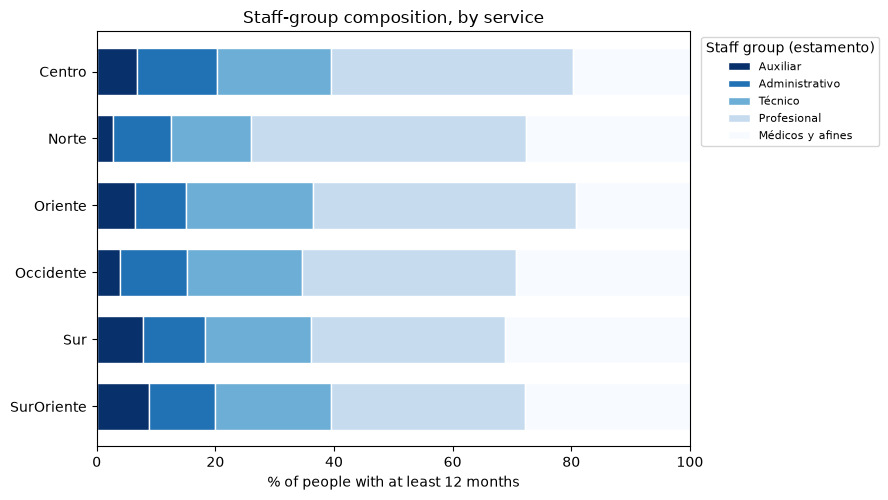

In [10]:
# COMPOSITION BY STAFF GROUP (%)
comp_pm = pd.crosstab(pm_all["servicio"], pm_all["estamento"], normalize="index").reindex(index=SERV, columns=ORDEN_EST) * 100
comp_p12 = pd.crosstab(p12_all["servicio"], p12_all["estamento"], normalize="index").reindex(index=SERV, columns=ORDEN_EST) * 100
print("% of person-months by staff group:")
display(comp_pm.round(1))
print(f"% of people with ≥{MESES_MINIMOS} months by staff group (denominator of persistence):")
display(comp_p12.round(1))

# FIGURE C1: COMPOSITION BY STAFF GROUP
fig, ax = plt.subplots(figsize=(9, 0.6 * len(SERV) + 1.5))
comp_p12.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, colormap="Blues_r", edgecolor="white", width=0.7)
ax.set_xlabel(f"% of people with at least {MESES_MINIMOS} months")
ax.set_ylabel("")
ax.set_title("Staff-group composition, by service")
ax.set_xlim(0, 100)
ax.legend(title="Staff group (estamento)", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c1_composition_by_staff_group.png", dpi=150)
plt.show()

In [11]:
# KPI BY STAFF GROUP AND SERVICE
n_est = (p12_all.pivot_table(index="estamento", columns="servicio", values="persistente", aggfunc="size")
                .reindex(index=ORDEN_EST, columns=SERV))
pers_est = (p12_all.pivot_table(index="estamento", columns="servicio", values="persistente", aggfunc="mean")
                   .reindex(index=ORDEN_EST, columns=SERV) * 100)
frec_est = (pm_all.pivot_table(index="estamento", columns="servicio", values="tiene_hhee", aggfunc="mean")
                  .reindex(index=ORDEN_EST, columns=SERV) * 100)
base_peso = pm_all[pm_all["tiene_hhee"] & (pm_all["rem_bruta"] > 0)]
peso_est = (base_peso.pivot_table(index="estamento", columns="servicio", values="pct_hhee_en_rem", aggfunc="median")
                     .reindex(index=ORDEN_EST, columns=SERV))

print(f"People with ≥{MESES_MINIMOS} months, by staff group:")
display(n_est)
print("Persistence rate (%):")
display(pers_est.round(1))
print("Overtime frequency (% of person-months):")
display(frec_est.round(1))
print("Weight of overtime in gross remuneration (median, %):")
display(peso_est.round(1))

People with ≥12 months, by staff group:


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
estamento,,,,,,
Auxiliar,121,17,117,77,120,155
Administrativo,239,59,156,217,160,198
Técnico,342,83,389,375,276,343
Profesional,724,283,806,696,505,577
Médicos y afines,350,169,347,566,479,492


Persistence rate (%):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
estamento,,,,,,
Auxiliar,55.400,76.500,19.700,44.200,60.000,38.100
Administrativo,44.800,49.200,23.700,24.000,41.200,41.900
Técnico,18.400,55.400,10.300,20.800,29.300,20.100
Profesional,16.300,11.000,6.000,17.800,24.400,6.400
Médicos y afines,2.600,9.500,0.900,2.800,1.500,5.900


Overtime frequency (% of person-months):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
estamento,,,,,,
Auxiliar,66.300,71.700,35.400,53.000,69.400,45.000
Administrativo,50.200,58.700,30.200,33.500,47.500,45.900
Técnico,28.700,63.500,26.500,36.800,45.600,30.100
Profesional,23.600,14.100,14.700,27.700,31.900,11.000
Médicos y afines,3.900,14.000,3.100,6.700,3.600,10.600


Weight of overtime in gross remuneration (median, %):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
estamento,,,,,,
Auxiliar,24.800,11.500,10.100,16.100,23.600,6.100
Administrativo,12.800,8.900,8.600,8.800,10.100,5.300
Técnico,15.400,12.900,7.600,10.400,12.100,4.400
Profesional,11.000,11.900,7.800,9.800,9.500,4.000
Médicos y afines,20.400,7.200,4.200,12.100,23.700,4.000


In [12]:
# STANDARDIZED PERSISTENCE RATE BY STAFF GROUP
composicion_ref = p12_all["estamento"].value_counts(normalize=True).reindex(ORDEN_EST)

estandarizacion = pd.DataFrame({
    "raw_rate_%": p12_all.groupby("servicio")["persistente"].mean().reindex(SERV) * 100,
    "standardized_rate_%": pers_est.mul(composicion_ref, axis=0).sum(min_count=1)
                           / pers_est.notna().mul(composicion_ref, axis=0).sum(),
})
estandarizacion["difference_pp"] = estandarizacion["standardized_rate_%"] - estandarizacion["raw_rate_%"]
print("Reference composition (all services, %):")
print((composicion_ref * 100).round(1))
estandarizacion.round(1)

Reference composition (all services, %):
estamento
Auxiliar            6.400
Administrativo     10.900
Técnico            19.200
Profesional        38.000
Médicos y afines   25.500
Name: proportion, dtype: float64


,raw_rate_%,standardized_rate_%,difference_pp
servicio,,,
Centro,20.500,18.800,-1.700
Norte,22.100,27.500,5.400
Oriente,8.300,8.300,-0.000
Occidente,15.700,16.900,1.200
Sur,22.700,23.600,1.000
SurOriente,15.700,14.800,-0.900


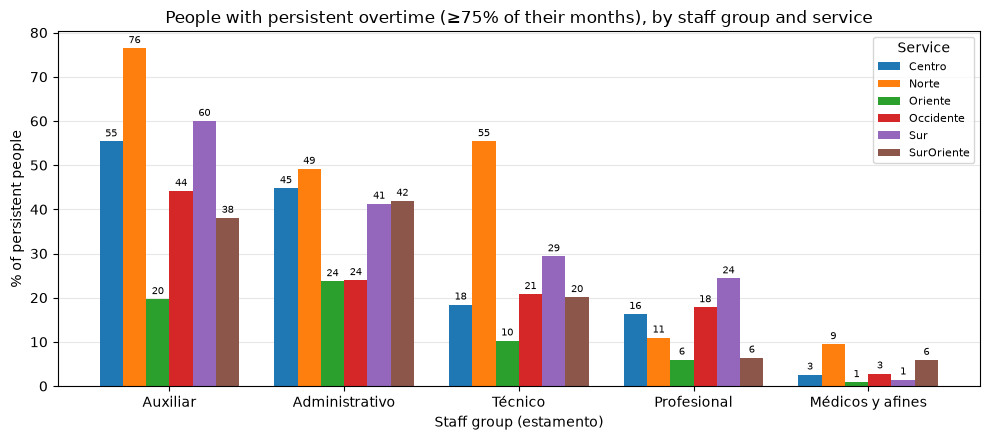

In [13]:
# FIGURE C2: PERSISTENCE BY STAFF GROUP AND SERVICE
x = np.arange(len(ORDEN_EST))
ancho = 0.8 / len(SERV)

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, s in enumerate(SERV):
    barras = ax.bar(x + (i - (len(SERV) - 1) / 2) * ancho, pers_est[s], width=ancho, color=COLOR[s], label=s)
    ax.bar_label(barras, labels=[f"{v:.0f}" if pd.notna(v) else "" for v in pers_est[s]], fontsize=7, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(ORDEN_EST)
ax.set_xlabel("Staff group (estamento)")
ax.set_ylabel("% of persistent people")
ax.set_title(f"People with persistent overtime (≥{UMBRAL_PERSISTENCIA}% of their months), by staff group and service")
ax.legend(title="Service", fontsize=8)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c2_persistence_by_staff_group_service.png", dpi=150)
plt.show()

### 2.2 Distributions by service

The three variables that support the KPIs are compared with the same robust measures as in `EDA.ipynb` (median, IQR, MAD):
- Overtime hours per person-month, among people with overtime.
- Weight of overtime in gross remuneration, among people with overtime and remuneration greater than zero.
- Percentage of months with overtime per person (present ≥ 12 months), the variable to which the threshold is applied.

In [14]:
# SUMMARY OF DISTRIBUTIONS BY SERVICE
def resumen_dist(s):
    return pd.Series({
        "n": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "MAD": (s - s.median()).abs().median(),
        "p95": s.quantile(0.95),
        "max": s.max(),
    })

con_all = pm_all[pm_all["tiene_hhee"]]
print("Overtime hours per person-month (with overtime):")
display(con_all.groupby("servicio")["horas_hhee"].apply(resumen_dist).unstack().reindex(SERV).round(1))
print("Weight of overtime in gross remuneration, % (with overtime and remuneration > 0):")
display(base_peso.groupby("servicio")["pct_hhee_en_rem"].apply(resumen_dist).unstack().reindex(SERV).round(1))
print(f"% of months with overtime per person (present ≥ {MESES_MINIMOS} months):")
display(p12_all.groupby("servicio")["pct_meses_con_hhee"].apply(resumen_dist).unstack().reindex(SERV).round(1))

Overtime hours per person-month (with overtime):


,n,mean,median,std,IQR,MAD,p95,max
servicio,,,,,,,,
Centro,11805.000,51.100,36.000,48.800,57.000,24.000,147.000,431.000
Norte,3982.000,35.600,25.000,29.200,32.000,13.000,94.000,206.000
Oriente,7873.000,33.400,23.000,32.100,34.000,14.000,105.000,543.000
Occidente,12479.000,42.900,29.000,41.800,47.000,18.000,122.000,770.000
Sur,10845.000,45.700,31.000,43.900,49.000,19.000,134.000,555.000
SurOriente,9277.000,14.800,13.000,10.700,14.000,7.000,36.000,165.000


Weight of overtime in gross remuneration, % (with overtime and remuneration > 0):


,n,mean,median,std,IQR,MAD,p95,max
servicio,,,,,,,,
Centro,11802.000,17.200,14.600,14.300,17.500,8.700,41.500,451.600
Norte,3982.000,14.700,10.900,15.600,12.400,5.800,38.400,106.500
Oriente,7872.000,10.300,8.100,8.800,10.000,4.600,26.600,131.800
Occidente,12425.000,19.200,10.400,291.000,13.900,6.000,45.800,31815.400
Sur,10831.000,17.900,12.400,33.000,16.300,7.300,43.600,1564.400
SurOriente,9277.000,6.100,4.800,9.200,5.000,2.500,12.100,100.000


% of months with overtime per person (present ≥ 12 months):


,n,mean,median,std,IQR,MAD,p95,max
servicio,,,,,,,,
Centro,1776.000,27.800,0.000,37.300,58.300,0.000,100.000,100.000
Norte,611.000,26.700,0.000,39.200,62.500,0.000,100.000,100.000
Oriente,1815.000,17.900,0.000,28.000,26.100,0.000,83.300,100.000
Occidente,1931.000,25.700,4.300,33.600,52.200,4.300,91.300,100.000
Sur,1540.000,30.700,4.500,38.300,66.700,4.500,100.000,100.000
SurOriente,1765.000,21.900,0.000,34.600,33.300,0.000,100.000,100.000


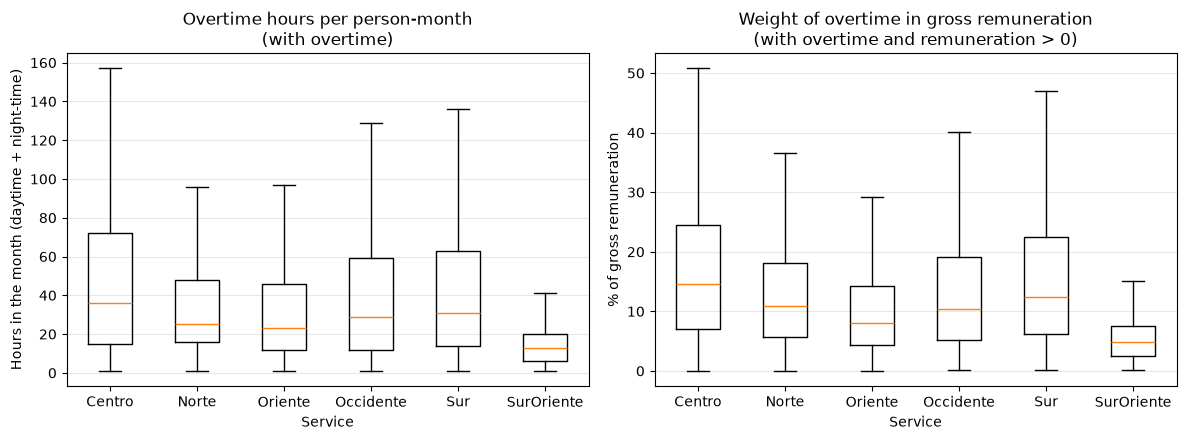

In [15]:
# FIGURE C3: DISTRIBUTION OF HOURS AND WEIGHT BY SERVICE
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot([con_all.loc[con_all["servicio"] == s, "horas_hhee"] for s in SERV], showfliers=False)
axes[0].set_title("Overtime hours per person-month\n(with overtime)")
axes[0].set_ylabel("Hours in the month (daytime + night-time)")

axes[1].boxplot([base_peso.loc[base_peso["servicio"] == s, "pct_hhee_en_rem"] for s in SERV], showfliers=False)
axes[1].set_title("Weight of overtime in gross remuneration\n(with overtime and remuneration > 0)")
axes[1].set_ylabel("% of gross remuneration")

for ax in axes:
    ax.set_xticks(range(1, len(SERV) + 1))
    ax.set_xticklabels(SERV)
    ax.set_xlabel("Service")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c3_distribution_hours_weight.png", dpi=150)
plt.show()

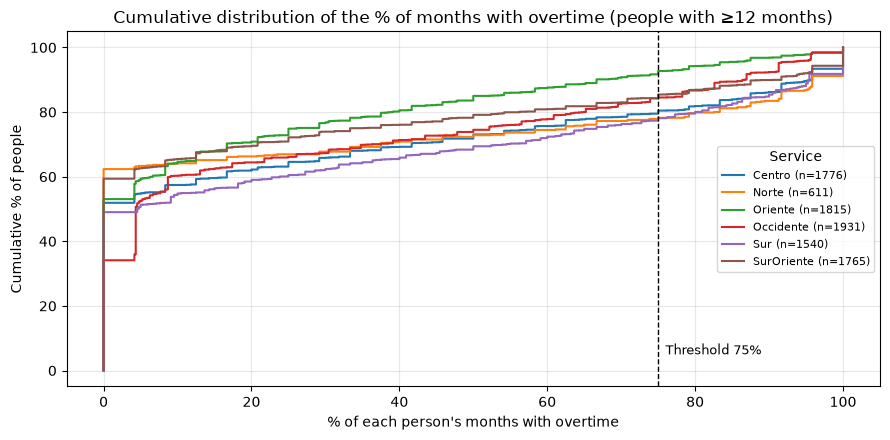

In [16]:
# FIGURE C4: CUMULATIVE DISTRIBUTION OF THE % OF MONTHS WITH OVERTIME
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SERV:
    v = np.sort(p12_all.loc[p12_all["servicio"] == s, "pct_meses_con_hhee"])
    ax.step(v, np.arange(1, len(v) + 1) / len(v) * 100, where="post", color=COLOR[s], label=f"{s} (n={len(v)})")
ax.axvline(UMBRAL_PERSISTENCIA, color="black", linestyle="--", linewidth=1)
ax.text(UMBRAL_PERSISTENCIA + 1, 5, f"Threshold {UMBRAL_PERSISTENCIA}%", fontsize=9)
ax.set_xlabel("% of each person's months with overtime")
ax.set_ylabel("Cumulative % of people")
ax.set_title(f"Cumulative distribution of the % of months with overtime (people with ≥{MESES_MINIMOS} months)")
ax.legend(title="Service", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c4_ecdf_persistence_by_service.png", dpi=150)
plt.show()

### 2.3 Monthly series and between-year comparison

- **Monthly series by service** of the frequency, the cases above 40 daytime hours, the median amount paid per hour, the weight and the spending. The amount per hour serves as a recording control: a sudden change in one month suggests a change in how amounts are reported (like August 2025 in Centro).
- **Comparison between the two years** (September to August), in total and by staff group, for each service.

In [17]:
# MONTHLY SERIES BY SERVICE
con_all = pm_all[pm_all["tiene_hhee"]].copy()
con_all["monto_por_hora"] = con_all["monto_hhee"] / con_all["horas_hhee"]

frec_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="tiene_hhee", aggfunc="mean").reindex(columns=SERV) * 100
sobre_40_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="sobre_40", aggfunc="sum").reindex(columns=SERV)
monto_hora_mes = con_all.pivot_table(index="periodo", columns="servicio", values="monto_por_hora", aggfunc="median").reindex(columns=SERV)
peso_mes = base_peso.pivot_table(index="periodo", columns="servicio", values="pct_hhee_en_rem", aggfunc="median").reindex(columns=SERV)
gasto_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="monto_hhee", aggfunc="sum").reindex(columns=SERV) / 1e6

print("Monthly frequency (%):");                        display(frec_mes.round(1))
print("Person-months with more than 40 daytime hours:");  display(sobre_40_mes)
print("Median amount paid per hour ($):");              display(monto_hora_mes.round(0))
print("Median weight in gross remuneration (%):");      display(peso_mes.round(1))
print("Monthly overtime spending (millions of $):");    display(gasto_mes.round(1))

Monthly frequency (%):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,29.800,30.800,23.700,22.600,NaN,22.800
2024-10,29.800,30.900,20.400,23.500,NaN,22.900
2024-11,29.800,32.000,20.700,22.900,32.200,23.600
2024-12,29.700,28.700,19.600,23.700,32.300,23.100
2025-01,29.600,29.800,19.800,22.900,32.900,23.000
2025-02,27.700,25.500,18.900,27.700,31.800,22.900
2025-03,27.800,28.600,16.700,25.300,33.400,22.600
2025-04,28.200,25.400,17.100,24.700,32.900,21.900
2025-05,28.400,27.400,13.200,23.300,30.900,22.700


Person-months with more than 40 daytime hours:


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,2.000,0.000,0.000,1.000,NaN,5.000
2024-10,2.000,0.000,0.000,0.000,NaN,3.000
2024-11,2.000,0.000,0.000,1.000,3.000,1.000
2024-12,6.000,0.000,0.000,1.000,0.000,4.000
2025-01,99.000,1.000,1.000,1.000,1.000,2.000
2025-02,6.000,1.000,0.000,5.000,0.000,3.000
2025-03,4.000,1.000,0.000,2.000,2.000,0.000
2025-04,8.000,1.000,1.000,1.000,0.000,1.000
2025-05,5.000,2.000,1.000,4.000,0.000,1.000


Median amount paid per hour ($):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,4662.000,5748.000,4634.000,4113.000,NaN,4038.000
2024-10,4556.000,5677.000,4787.000,4622.000,NaN,3661.000
2024-11,4438.000,5677.000,4778.000,4110.000,3764.000,3694.000
2024-12,4558.000,5810.000,4393.000,4312.000,3952.000,3694.000
2025-01,4644.000,5848.000,4488.000,4373.000,4046.000,3804.000
2025-02,4498.000,5765.000,4512.000,4232.000,3881.000,3816.000
2025-03,4646.000,6099.000,4539.000,4367.000,3972.000,3816.000
2025-04,4626.000,5951.000,4560.000,4512.000,3914.000,3850.000
2025-05,4738.000,7258.000,4671.000,4693.000,4163.000,3850.000


Median weight in gross remuneration (%):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,14.400,10.900,8.700,12.600,NaN,4.700
2024-10,14.400,12.800,9.800,15.300,NaN,5.300
2024-11,14.800,11.600,10.000,11.000,12.000,5.000
2024-12,15.400,9.400,8.300,12.400,12.900,4.200
2025-01,20.400,9.100,9.000,12.500,13.400,4.300
2025-02,16.000,12.800,9.200,11.400,14.800,6.300
2025-03,14.700,8.900,7.200,7.900,11.600,3.900
2025-04,20.500,12.300,8.600,11.500,13.600,5.900
2025-05,15.200,12.400,3.900,10.900,13.200,5.900


Monthly overtime spending (millions of $):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,152.700,56.000,65.100,111.300,NaN,41.100
2024-10,147.100,53.200,65.900,147.700,NaN,36.400
2024-11,155.100,55.300,66.400,118.800,126.000,37.000
2024-12,156.000,44.900,53.900,129.700,128.400,37.800
2025-01,191.800,47.800,61.500,137.900,140.800,38.200
2025-02,142.300,43.000,60.000,138.100,130.900,38.800
2025-03,145.100,49.800,44.500,118.000,126.200,32.700
2025-04,178.600,45.600,51.200,129.300,131.300,37.500
2025-05,153.000,52.600,18.900,127.900,126.700,39.500


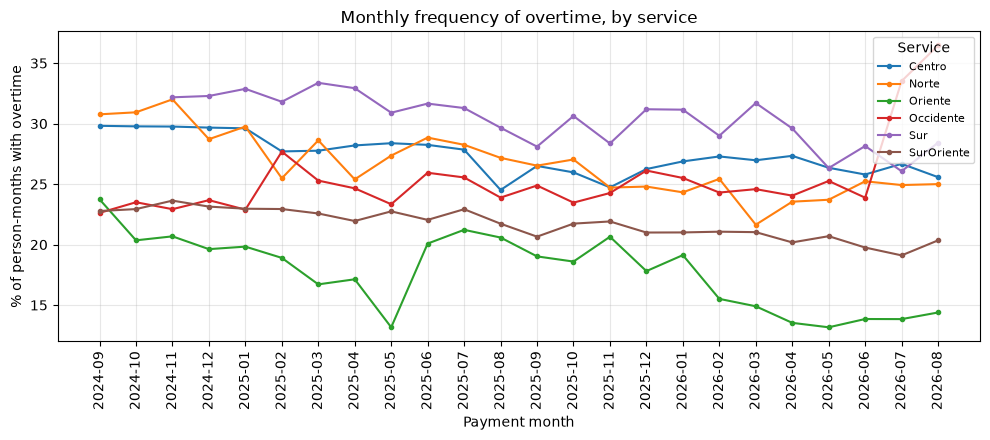

In [18]:
# FIGURE C5: MONTHLY FREQUENCY BY SERVICE
fig, ax = plt.subplots(figsize=(10, 4.5))
for s in SERV:
    ax.plot(frec_mes.index, frec_mes[s], marker="o", markersize=3, linewidth=1.5, color=COLOR[s], label=s)
ax.set_title("Monthly frequency of overtime, by service")
ax.set_xlabel("Payment month")
ax.set_ylabel("% of person-months with overtime")
ax.tick_params(axis="x", rotation=90)
ax.legend(title="Service", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c5_monthly_frequency_by_service.png", dpi=150)
plt.show()

In [19]:
# BETWEEN-YEAR COMPARISON (SAME MONTHS), BY SERVICE
pm_all["anio"] = np.where(pm_all["periodo"] <= "2025-08", "Sep 2024 - Aug 2025", "Sep 2025 - Aug 2026")

def resumen_anio(t):
    c = t[t["tiene_hhee"]]
    return pd.Series({
        "person_months": len(t),
        "frequency_%": t["tiene_hhee"].mean() * 100,
        "median_hours": c["horas_hhee"].median(),
        "median_weight_%": c.loc[c["rem_bruta"] > 0, "pct_hhee_en_rem"].median(),
        "overtime_spend_MM": t["monto_hhee"].sum() / 1e6,
    })

print("All months:")
display(pm_all.groupby(["servicio", "anio"])[pm_all.columns].apply(resumen_anio).unstack().reindex(SERV).round(1))
print("Without atypical months (MESES_ATIPICOS):")
sin_atipicos = pm_all[~pm_all["flag_mes_atipico"]]
display(sin_atipicos.groupby(["servicio", "anio"])[sin_atipicos.columns].apply(resumen_anio).unstack().reindex(SERV).round(1))
print("Frequency by service, staff group and year (%):")
(pm_all.pivot_table(index=["servicio", "estamento"], columns="anio", values="tiene_hhee", aggfunc="mean")
       .reindex(SERV, level=0).mul(100).round(1))

All months:


person_months                             frequency_%  \
anio       Sep 2024 - Aug 2025 Sep 2025 - Aug 2026 Sep 2024 - Aug 2025   
servicio                                                                 
Centro               21245.000           21875.000              28.400   
Norte                 7395.000            7554.000              28.600   
Oriente              21896.000           22461.000              19.300   
Occidente            24636.000           24508.000              24.300   
Sur                  16323.000           19439.000              31.900   
SurOriente           21560.000           21161.000              22.700   

                                      median_hours                      \
anio       Sep 2025 - Aug 2026 Sep 2024 - Aug 2025 Sep 2025 - Aug 2026   
servicio                                                                 
Centro                  26.400              37.000              35.000   
Norte                   24.700              25.000              25.000   
Oriente                 16.200              23.000              23.000   
Occidente               26.500              34.000              26.000   
Sur                     29.000              32.500              30.000   
SurOriente              20.700              14.000              13.000   

               median_weight_%                       overtime_spend_MM  \
anio       Sep 2024 - Aug 2025 Sep 2025 - Aug 2026 Sep 2024 - Aug 2025   
servicio                                                                 
Centro                  15.100              14.100            1791.100   
Norte                   11.500              10.400             612.600   
Oriente                  8.400               7.700             677.900   
Occidente               11.400               9.800            1560.100   
Sur                     13.100              11.900            1283.600   
SurOriente               4.900               4.700             443.000   

                                
anio       Sep 2025 - Aug 2026  
servicio                        
Centro                1635.300  
Norte                  566.900  
Oriente                557.700  
Occidente             1577.800  
Sur                   1314.100  
SurOriente             377.200

Without atypical months (MESES_ATIPICOS):


person_months                             frequency_%  \
anio       Sep 2024 - Aug 2025 Sep 2025 - Aug 2026 Sep 2024 - Aug 2025   
servicio                                                                 
Centro               19489.000           21875.000              28.300   
Norte                 7395.000            7554.000              28.600   
Oriente              21896.000           22461.000              19.300   
Occidente            24636.000           24508.000              24.300   
Sur                  16323.000           18378.000              31.900   
SurOriente           21560.000           21161.000              22.700   

                                      median_hours                      \
anio       Sep 2025 - Aug 2026 Sep 2024 - Aug 2025 Sep 2025 - Aug 2026   
servicio                                                                 
Centro                  26.400              36.000              35.000   
Norte                   24.700              25.000              25.000   
Oriente                 16.200              23.000              23.000   
Occidente               26.500              34.000              26.000   
Sur                     28.900              32.500              30.000   
SurOriente              20.700              14.000              13.000   

               median_weight_%                       overtime_spend_MM  \
anio       Sep 2024 - Aug 2025 Sep 2025 - Aug 2026 Sep 2024 - Aug 2025   
servicio                                                                 
Centro                  14.700              14.100            1599.400   
Norte                   11.500              10.400             612.600   
Oriente                  8.400               7.700             677.900   
Occidente               11.400               9.800            1560.100   
Sur                     13.100              11.800            1283.600   
SurOriente               4.900               4.700             443.000   

                                
anio       Sep 2025 - Aug 2026  
servicio                        
Centro                1635.300  
Norte                  566.900  
Oriente                557.700  
Occidente             1577.800  
Sur                   1232.800  
SurOriente             377.200

Frequency by service, staff group and year (%):


anio                         Sep 2024 - Aug 2025  Sep 2025 - Aug 2026
servicio   estamento                                                 
Centro     Administrativo                 51.000               49.300
           Auxiliar                       68.900               63.700
           Médicos y afines                4.100                3.700
           Profesional                    24.500               22.700
           Técnico                        29.700               27.800
Norte      Administrativo                 58.100               59.300
           Auxiliar                       72.000               71.400
           Médicos y afines               15.900               12.300
           Profesional                    16.900               11.400
           Técnico                        60.300               67.000
Oriente    Administrativo                 31.000               29.400
           Auxiliar                       36.400               34.300
           Médicos y afines                3.200                2.900
           Profesional                    16.700               12.700
           Técnico                        28.900               24.300
Occidente  Administrativo                 31.100               36.100
           Auxiliar                       53.200               52.900
           Médicos y afines                6.400                7.000
           Profesional                    26.500               28.800
           Técnico                        35.300               38.300
Sur        Administrativo                 46.800               48.100
           Auxiliar                       71.700               67.500
           Médicos y afines                4.000                3.400
           Profesional                    34.600               29.600
           Técnico                        48.100               43.500
SurOriente Administrativo                 47.700               44.100
           Auxiliar                       45.400               44.500
           Directivo                         NaN                0.000
           Médicos y afines               11.100               10.100
           Profesional                    12.300                9.600
           Técnico                        30.600               29.700

### 2.4 Spending and KPI sensitivity

- **Overtime spending** by service and staff group, and the part that belongs to persistent people.
- **Sensitivity of the persistence threshold** (50%, 75% and 90%) in each service.
- **KPI with and without flagged cases**, as in section 6.4 of `EDA.ipynb`, for each service.

In [20]:
# OVERTIME SPENDING BY SERVICE AND STAFF GROUP
gasto = pm_all.groupby("servicio").agg(
    person_months=("monto_hhee", "size"),
    total_spend_MM=("monto_hhee", "sum"),
).reindex(SERV)
gasto["total_spend_MM"] /= 1e6
gasto["persistent_spend_MM"] = pm_all[pm_all["persistente"]].groupby("servicio")["monto_hhee"].sum().reindex(SERV) / 1e6
gasto["%_persistent"] = gasto["persistent_spend_MM"] / gasto["total_spend_MM"] * 100
gasto["spend_per_person_month"] = gasto["total_spend_MM"] * 1e6 / gasto["person_months"]
gasto["%_gross_rem"] = pm_all.groupby("servicio")["monto_hhee"].sum() / pm_all.groupby("servicio")["rem_bruta"].sum() * 100
display(gasto.round(1))

print("Spending by staff group (% of each service's overtime spending):")
gasto_est = (pm_all.pivot_table(index="estamento", columns="servicio", values="monto_hhee", aggfunc="sum")
                   .reindex(index=ORDEN_EST, columns=SERV))
(gasto_est / gasto_est.sum() * 100).round(1)

,person_months,total_spend_MM,persistent_spend_MM,%_persistent,spend_per_person_month,%_gross_rem
servicio,,,,,,
Centro,43120,3426.500,2504.000,73.100,79464.000,4.000
Norte,14949,1179.500,947.200,80.300,78900.700,3.000
Oriente,44357,1235.600,490.900,39.700,27855.500,1.300
Occidente,49144,3137.900,1664.300,53.000,63851.400,2.900
Sur,35762,2597.700,1586.600,61.100,72637.900,3.400
SurOriente,42721,820.200,501.800,61.200,19198.500,0.900


Spending by staff group (% of each service's overtime spending):


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
estamento,,,,,,
Auxiliar,19.400,3.900,10.500,6.200,17.200,12.600
Administrativo,14.600,9.400,9.500,7.700,8.400,17.600
Técnico,14.000,24.300,22.100,17.100,18.600,16.100
Profesional,43.400,36.000,53.200,49.600,35.800,19.400
Médicos y afines,8.600,26.400,4.700,19.400,20.000,34.300


In [21]:
# SENSITIVITY OF THE PERSISTENCE THRESHOLD, BY SERVICE
umbrales = [50, 75, 90]
sens_umbral = pd.DataFrame({
    f"≥{u}%": p12_all.groupby("servicio")["pct_meses_con_hhee"].apply(lambda s: (s >= u).mean() * 100)
    for u in umbrales
}).reindex(SERV)
sens_umbral.loc["Total"] = [(p12_all["pct_meses_con_hhee"] >= u).mean() * 100 for u in umbrales]
display(sens_umbral.round(1))

print("By staff group and service:")
pd.concat({
    f"≥{u}%": p12_all.pivot_table(index="estamento", columns="servicio", values="pct_meses_con_hhee",
                                  aggfunc=lambda s, u=u: (s >= u).mean() * 100).reindex(index=ORDEN_EST, columns=SERV)
    for u in umbrales
}, axis=1).round(1)

,≥50%,≥75%,≥90%
servicio,,,
Centro,28.200,20.500,14.000
Norte,27.700,22.100,16.500
Oriente,16.400,8.300,3.200
Occidente,26.200,15.700,7.700
Sur,31.600,22.700,15.200
SurOriente,21.800,15.700,10.100
Total,24.800,16.700,10.300


By staff group and service:


≥50%                                              ≥75%  \
servicio         Centro  Norte Oriente Occidente    Sur SurOriente Centro   
estamento                                                                   
Auxiliar         72.700 82.400  39.300    63.600 72.500     45.200 55.400   
Administrativo   53.100 59.300  34.000    34.100 50.000     47.500 44.800   
Técnico          29.200 69.900  23.400    39.500 46.000     30.300 18.400   
Profesional      23.900 13.100  12.300    29.500 35.000     10.700 16.300   
Médicos y afines  3.700 14.800   2.600     5.100  3.300     11.000  2.600   

                                                              ≥90%         \
servicio          Norte Oriente Occidente    Sur SurOriente Centro  Norte   
estamento                                                                   
Auxiliar         76.500  19.700    44.200 60.000     38.100 37.200 47.100   
Administrativo   49.200  23.700    24.000 41.200     41.900 34.300 44.100   
Técnico          55.400  10.300    20.800 29.300     20.100 10.800 39.800   
Profesional      11.000   6.000    17.800 24.400      6.400 11.300  9.200   
Médicos y afines  9.500   0.900     2.800  1.500      5.900  0.600  4.700   

                                                      
servicio         Oriente Occidente    Sur SurOriente  
estamento                                             
Auxiliar           7.700    29.900 47.500     30.300  
Administrativo    12.200    15.700 31.900     28.300  
Técnico            2.100     8.800 17.000     13.400  
Profesional        2.600     7.900 15.400      3.500  
Médicos y afines   0.300     0.700  0.200      1.800

In [22]:
# KPI BEFORE AND AFTER EXCLUDING FLAGGED CASES, BY SERVICE
escenarios = {
    "Original": pm_all,
    "Without atypical months": pm_all[~pm_all["flag_mes_atipico"]],
    "Without impossible values": pm_all[~pm_all["flag_pct_imposible"]],
    "Without extreme hours": pm_all[~pm_all["flag_horas_extremas"]],
    "Without any flag": pm_all[~pm_all.filter(like="flag_").any(axis=1)],
}
kpis_escenario = {nombre: kpis_por_servicio(t) for nombre, t in escenarios.items()}

for kpi in ["persistence_rate_%", "frequency_%", "weight_median_%"]:
    print(kpi)
    display(pd.DataFrame({nombre: t[kpi] for nombre, t in kpis_escenario.items()}).T.round(1))

persistence_rate_%


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente,Total
Original,20.500,22.100,8.300,15.700,22.700,15.700,16.700
Without atypical months,19.900,22.100,8.300,15.700,22.800,15.700,16.600
Without impossible values,20.400,22.100,8.300,15.700,22.400,15.700,16.700
Without extreme hours,19.400,21.600,8.000,15.300,21.200,15.600,16.100
Without any flag,19.000,21.600,8.000,15.600,21.500,15.600,16.100


frequency_%


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente,Total
Original,27.400,26.600,17.700,25.400,30.300,21.700,24.500
Without atypical months,27.300,26.600,17.700,25.400,30.300,21.700,24.400
Without impossible values,27.400,26.600,17.700,25.200,30.200,21.700,24.400
Without extreme hours,26.500,25.900,16.800,24.600,29.300,21.600,23.700
Without any flag,26.600,26.000,16.900,25.000,29.400,21.600,23.800


weight_median_%


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente,Total
Original,14.600,10.900,8.100,10.400,12.400,4.800,9.400
Without atypical months,14.400,10.900,8.100,10.400,12.400,4.800,9.400
Without impossible values,14.600,10.900,8.100,10.300,12.300,4.800,9.400
Without extreme hours,14.100,10.500,7.300,10.000,11.700,4.800,9.000
Without any flag,13.900,10.500,7.300,9.900,11.600,4.800,9.000


### 2.5 Interpretation of the comparison

**Coverage.** Six services were loaded. In the common window (September 2024 – August 2026) there are 238,583 rows, 230,053 person-months and 9,438 people present at least 12 months. Centro reproduces exactly the figures of `EDA.ipynb` (43,120 person-months, 1,776 people with ≥12 months, 364 persistent). Sur covers 22 of the 24 months (no September or October 2024) and its October 2025 is incomplete, so it is flagged as an atypical month.

**Persistence.** The total rate is 16.7% (1,580 of 9,438 people). It is higher in Sur (22.7%), Norte (22.1%) and Centro (20.5%), intermediate in Occidente and Sur Oriente (15.7%) and much lower in Oriente (8.3%).

**Staff-group composition.** Standardizing by staff group changes the order little, except in Norte: its standardized rate rises to 27.5% (+5.4 pp), because it has fewer technical staff than the total (13.6% versus 19.2%) and in Norte technical staff are very persistent (55.4%). Centro falls to 18.8% (−1.7 pp), because it has fewer physicians (19.7% versus 25.5%), the staff group with the lowest persistence. Oriente stays the same (8.3%): its low rate is not explained by composition.

**Pattern by staff group.** Auxiliary and administrative staff are the two staff groups with the highest persistence in five of the six services; in Norte, technical staff take second place. Persistence of auxiliary staff ranges from 19.7% (Oriente) to 76.5% (Norte). Physicians have the lowest persistence in every service (between 0.9% and 9.5%). Technical staff vary the most between services: 55.4% in Norte versus 10.3% in Oriente.

**Intensity, weight and spending.** Among people with overtime, the monthly median ranges from 13 hours (Sur Oriente) to 36 hours (Centro), and the median weight in gross remuneration from 4.8% (Sur Oriente) to 14.6% (Centro). Total overtime spending over the 24 months is $12,397 million; Centro ($3,427 MM) and Occidente ($3,138 MM) are the largest. Persistent people account for between 39.7% (Oriente) and 80.3% (Norte) of their service's spending.

**Robustness.** When flagged cases (atypical months, impossible values and extreme hours) are excluded, the persistence rate changes by at most 1.5 pp per service (Centro: 20.5% → 19.0%; Sur: 22.7% → 21.5%) and the order between services is maintained. With thresholds of 50%, 75% and 90%, Sur, Norte and Centro remain the three highest and Oriente the lowest.

**Caveats.**
- *Sur:* the between-year comparison is not direct, because its first year has 10 months instead of 12 (16,323 versus 19,439 person-months). Its first-year spending is underestimated.
- *Sur Oriente:* its hours are much lower (median 13, p95 36), it concentrates 7,955 of the 10,069 rows with holiday hours and has no row with paid hours without entitlement. It may be a different way of recording hours; this must be verified before concluding that it uses less overtime.
- *Occidente:* 13,558 net remunerations could not be converted and there are impossible weight values (maximum 31,815%). They are flagged and the median is robust to them.
- *Identity:* without a national ID, 135 names appear in more than one service and are counted as different people.

**What this does not allow us to conclude.** These are descriptive associations, not causes. High persistence indicates that certain people receive overtime recurrently; by itself it does not prove that those positions are understaffed.

## 3. Data validation (Part 3 · rubric C)

*Note on order:* section 0 must build the data before the checks can run, so section 3 comes after the exploratory section 2 in this notebook.

### 3.1 Data dictionary

| Variable | Expected type | Acceptable values | Missing-value meaning |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |

> TODO (Role B): complete the dictionary for the variables used in the KPI (including `Nombre completo`, `Estamento`, the three overtime fields, gross remuneration and the period).

### 3.2 Quality checks

The checks of `EDA.ipynb` are repeated in each service, to detect recording problems specific to each one before comparing:
1. Values that cannot be converted in amounts, overtime hours and dates.
2. "-" values in additional remuneration and bonuses, by month.
3. Exact duplicates.
4. People with more than one record in the same month (the unit of observation).
5. Staff-group changes between consecutive months (the December 2025 error in Centro).
6. Holiday hours, overtime entitlement versus paid hours, region and distinct positions.
7. People with the same name in more than one service.
8. Aggregation control (person-month sums equal payroll sums).

In [23]:
# CONVERSIONS BY SERVICE
pd.DataFrame(controles).set_index("service")

,rows,unconverted_rem_bruta,unconverted_rem_liquida,unconverted_rem_adicionales,unconverted_bonos,empty_diurnas,other_format_diurnas,empty_nocturnas,other_format_nocturnas,empty_festivas,other_format_festivas,unconverted_fecha_inicio,unconverted_fecha_termino
service,,,,,,,,,,,,,
Centro,44777,0,0,1825,3065,0,0,0,0,0,0,0,0
Norte,15790,0,1,4541,4217,0,0,0,2,0,0,0,0
Oriente,47260,0,1875,21837,14712,0,0,0,0,0,0,0,1
Occidente,54995,0,13558,9165,4547,0,0,0,0,0,0,0,354
Sur,39130,0,0,0,0,0,0,0,0,0,0,0,0
SurOriente,44780,0,0,44780,44780,0,0,0,0,0,0,0,0


**Result and action:** *flagged as limitation / retained.* Gross remuneration and the overtime fields convert fully (the few "other format" night-time values are in Norte: 2). Net remuneration fails to convert in Occidente (13,558) and Oriente (1,875); it is not used in any KPI. Additional pay and bonuses come as "-" and become missing by design (all of SurOriente), also outside the KPIs.

In [24]:
# "-" VALUES BY MONTH AND SERVICE (%)
aux = nomina[["servicio", "periodo"]].copy()
aux["guion_rem_adicionales"] = nomina["rem_adicionales"].isna()
aux["guion_bonos"] = nomina["bonos"].isna()
aux["bonos_positivos"] = nomina["bonos"].gt(0)

for col in ["guion_rem_adicionales", "guion_bonos", "bonos_positivos"]:
    print(col)
    display((aux.pivot_table(index="periodo", columns="servicio", values=col, aggfunc="mean")
                .reindex(columns=SERV) * 100).round(1))

guion_rem_adicionales


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,0.000,28.500,38.100,100.000,NaN,100.000
2024-10,0.000,29.200,46.100,100.000,NaN,100.000
2024-11,0.000,29.300,34.500,100.000,0.000,100.000
2024-12,0.000,29.100,0.000,100.000,0.000,100.000
2025-01,100.000,29.300,0.000,0.000,0.000,100.000
2025-02,0.000,30.400,100.000,0.000,0.000,100.000
2025-03,0.000,29.500,35.300,0.000,0.000,100.000
2025-04,0.000,27.700,0.000,0.000,0.000,100.000
2025-05,0.000,26.900,82.400,0.000,0.000,100.000


guion_bonos


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,0.000,28.500,61.900,0.000,NaN,100.000
2024-10,0.000,29.200,36.500,100.000,NaN,100.000
2024-11,0.000,29.300,0.000,100.000,0.000,100.000
2024-12,3.900,29.100,0.400,0.000,0.000,100.000
2025-01,0.000,29.300,0.000,0.000,0.000,100.000
2025-02,0.000,30.400,0.000,0.000,0.000,100.000
2025-03,0.000,29.500,0.100,0.000,0.000,100.000
2025-04,0.000,27.700,0.000,0.000,0.000,100.000
2025-05,80.400,26.900,100.000,0.000,0.000,100.000


bonos_positivos


servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,65.200,0.000,23.900,53.400,NaN,0.000
2024-10,0.000,0.000,0.000,0.000,NaN,0.000
2024-11,16.200,0.000,62.900,0.000,0.000,0.000
2024-12,29.000,0.000,76.900,63.400,30.600,0.000
2025-01,30.900,0.000,0.000,0.000,0.300,0.000
2025-02,70.800,0.000,0.000,0.000,0.000,0.000
2025-03,70.800,0.000,65.700,58.800,35.700,0.000
2025-04,0.000,0.000,0.000,0.000,0.000,0.000
2025-05,0.000,0.000,0.000,0.000,0.000,0.000


**Result and action:** *retained, flagged as limitation.* The share of "-" varies a lot by service and month (for example 100% in Occidente until December 2024, and in SurOriente every month). These two fields are not used in the KPIs (overtime and gross remuneration are), so the values are left missing and not imputed.

In [25]:
# EXACT DUPLICATES AND RECORDS PER PERSON-MONTH
duplicadas = nomina_v[nomina_v.duplicated(subset=ORIGINALES + ["servicio"], keep=False)]
duplicadas_hhee = (duplicadas["horas_diurnas"] + duplicadas["horas_nocturnas"]) > 0

repeticiones = nomina_v.groupby(["servicio", "periodo", "Nombre completo"]).size()

calidad = pd.DataFrame({
    "extra_copies": nomina_v.duplicated(subset=ORIGINALES + ["servicio"]).groupby(nomina_v["servicio"]).sum(),
    "duplicated_rows_with_overtime": duplicadas_hhee.groupby(duplicadas["servicio"]).sum(),
    "rows": nomina_v.groupby("servicio").size(),
    "person_months": repeticiones.groupby("servicio").size(),
    "person_months_with_more_than_one_record": (repeticiones > 1).groupby("servicio").sum(),
    "max_records_per_person_month": repeticiones.groupby("servicio").max(),
}).reindex(SERV).fillna(0)
calidad["extra_rows_%"] = (calidad["rows"] - calidad["person_months"]) / calidad["rows"] * 100
calidad.round(1)

,extra_copies,duplicated_rows_with_overtime,rows,person_months,person_months_with_more_than_one_record,max_records_per_person_month,extra_rows_%
servicio,,,,,,,
Centro,27,0.000,44777,43120,1507,6,3.700
Norte,0,0.000,15146,14949,197,2,1.300
Oriente,0,0.000,45386,44357,981,4,2.300
Occidente,0,0.000,52865,49144,3159,7,7.000
Sur,0,0.000,37353,35762,1473,5,4.300
SurOriente,0,0.000,43056,42721,320,3,0.800


**Result and action:** *retained with justification.* Every service has person-months with more than one row (extra rows between 0.8% and 7.0%). A person can hold several contracts in a month (data-generating process described in C1), so rows are not dropped: they are aggregated to person-month by summing hours and amounts (aggregation control below).

In [26]:
# STAFF-GROUP CHANGES BETWEEN CONSECUTIVE MONTHS, BY SERVICE
est = (nomina_v.groupby(["servicio", "periodo", "Nombre completo"])["Estamento"].first()
               .reset_index().sort_values(["servicio", "Nombre completo", "periodo"]))
est["estamento_mes_anterior"] = est.groupby(["servicio", "Nombre completo"])["Estamento"].shift(1)
cambios = est.dropna(subset=["estamento_mes_anterior"])
cambios = cambios[cambios["Estamento"] != cambios["estamento_mes_anterior"]]

cambios_mes = (cambios.pivot_table(index="periodo", columns="servicio", values="Estamento", aggfunc="size")
                      .reindex(index=VENTANA, columns=SERV).fillna(0).astype(int))
cambios_mes

servicio,Centro,Norte,Oriente,Occidente,Sur,SurOriente
periodo,,,,,,
2024-09,0,0,0,0,0,0
2024-10,0,0,19,1,0,5
2024-11,0,1,0,5,0,3
2024-12,1,1,4,3,4,5
2025-01,2,1,1,2,5,4
2025-02,1,2,1,3,3,2
2025-03,0,0,6,1,3,6
2025-04,0,0,1,3,3,4
2025-05,0,2,4,2,1,1


**Result and action:** *corrected.* Centro shows the known recording error in December 2025 and January 2026 (218 and 213 changes); the other services have a few changes per month. Each person is assigned their most frequent staff group (`estamento_modal`), which neutralizes the error.

In [27]:
# OTHER CHECKS BY SERVICE
tiene_hhee_fila = (nomina_v["horas_diurnas"] + nomina_v["horas_nocturnas"]) > 0
otros = pd.DataFrame({
    "rows_with_holiday_hours": (nomina_v["horas_festivas"] > 0).groupby(nomina_v["servicio"]).sum(),
    "overtime_without_entitlement": (tiene_hhee_fila & nomina_v["Derecho a horas extraordinarias"].str.strip().eq("No"))
                                    .groupby(nomina_v["servicio"]).sum(),
    "distinct_regions": nomina_v.groupby("servicio")["Región"].nunique(),
    "original_positions": nomina_v.groupby("servicio")["Cargo o función"].nunique(),
    "normalized_positions": nomina_v.groupby("servicio")["cargo"].nunique(),
    "distinct_staff_groups": nomina_v.groupby("servicio")["Estamento"].nunique(),
}).reindex(SERV)
display(otros)

print("Overtime entitlement versus paid hours (rows):")
pd.crosstab([nomina_v["servicio"], nomina_v["Derecho a horas extraordinarias"]], tiene_hhee_fila)

,rows_with_holiday_hours,overtime_without_entitlement,distinct_regions,original_positions,normalized_positions,distinct_staff_groups
servicio,,,,,,
Centro,0,207,1,95,80,5
Norte,432,120,1,770,744,5
Oriente,1682,1298,2,242,213,5
Occidente,0,420,1,131,116,5
Sur,0,65,1,84,74,6
SurOriente,7955,0,1,109,97,6


Overtime entitlement versus paid hours (rows):


col_0                                       False  True 
servicio   Derecho a horas extraordinarias              
Centro     No                               32555    207
           Sí                                 407  11608
Norte      No                               11081    120
           Sí                                  83   3862
Occidente  No                               40018    420
           Sí                                 119  12308
Oriente    No                               36488   1298
           Sí                                1011   6589
Sur        No                               22477     65
           Sí                                3912  10899
SurOriente No                               31153      0
           Sí                                2624   9279

**Result and action:** *retained, flagged as limitation.* Holiday hours are recorded in Norte, Oriente and especially SurOriente (7,955 rows), which may be a different way of recording hours (not verified). Rows with paid overtime but "No" entitlement exist in all services except SurOriente; they are kept because the KPI is based on payment. Position names are normalized (`cargo`) to reduce duplicates.

In [28]:
# PEOPLE WITH THE SAME NAME IN MORE THAN ONE SERVICE
serv_por_nombre = nomina_v.groupby("Nombre completo")["servicio"].nunique()
print("Names present in more than one service (in some month):", (serv_por_nombre > 1).sum())

mismo_mes = nomina_v.groupby(["periodo", "Nombre completo"])["servicio"].nunique()
print("Names present in more than one service in the same month, by month:")
(mismo_mes > 1).groupby("periodo").sum()

Names present in more than one service (in some month): 135
Names present in more than one service in the same month, by month:


periodo
2024-09    1
2024-10    2
2024-11    4
2024-12    3
2025-01    6
2025-02    3
2025-03    6
2025-04    4
2025-05    2
2025-06    4
2025-07    3
2025-08    6
2025-09    4
2025-10    8
2025-11    4
2025-12    4
2026-01    5
2026-02    6
2026-03    6
2026-04    9
2026-05    7
2026-06    6
2026-07    4
2026-08    5
Name: servicio, dtype: int64

**Result and action:** *flagged as limitation.* 135 names appear in more than one service. Without a national ID they cannot be linked, so each (service, name) is counted as a different person; this is carried into the split design (section 6.2).

In [29]:
# AGGREGATION CONTROL (is the sum equal in the payroll and in the person-month table?)
print("Aggregation control (is the sum equal in the payroll and in person-month?):")
for col in ["horas_diurnas", "horas_nocturnas", "monto_diurnas", "monto_nocturnas", "rem_bruta"]:
    iguales = nomina_v.groupby("servicio")[col].sum().eq(pm_all.groupby("servicio")[col].sum())
    print(f"{col}: {iguales.all()}")
print("Person-months without an assigned staff group:", pm_all["estamento"].isna().sum())

Aggregation control (is the sum equal in the payroll and in person-month?):


horas_diurnas: True
horas_nocturnas: True
monto_diurnas: True
monto_nocturnas: True


rem_bruta: True
Person-months without an assigned staff group: 0


**Result and action:** *verified.* Hours, amounts and gross remuneration add up identically before and after aggregating to person-month, so no values were lost or duplicated.

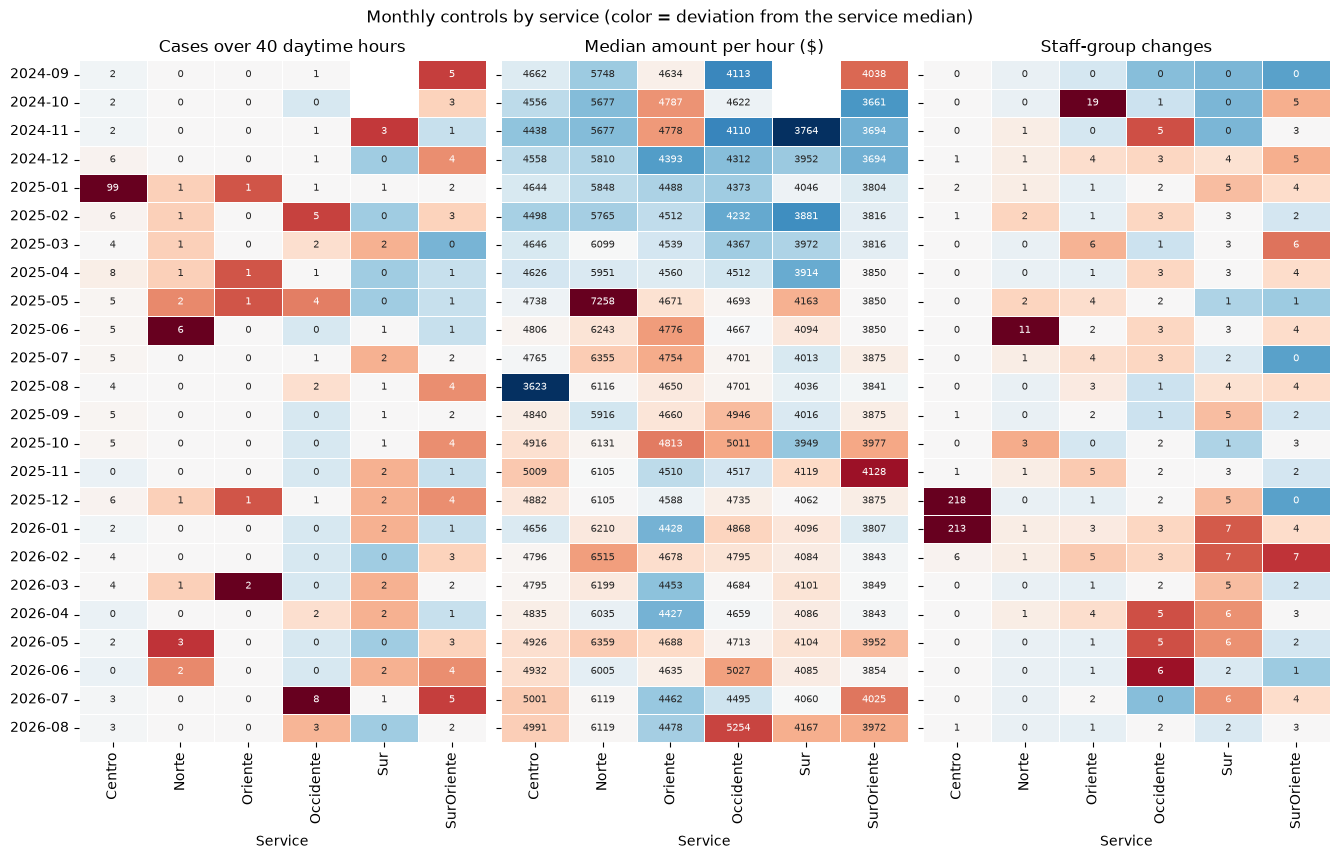

In [30]:
# FIGURE C6: MONTHLY RECORDING CONTROLS (HEATMAPS)
# The color is normalized within each service (column), to see months that deviate from the rest of their own service
paneles = {
    "Cases over 40 daytime hours": sobre_40_mes,
    "Median amount per hour ($)": monto_hora_mes,
    "Staff-group changes": cambios_mes,
}
fig, axes = plt.subplots(1, len(paneles), figsize=(4.5 * len(paneles), 0.28 * len(VENTANA) + 2), sharey=True)
for ax, (titulo, tabla) in zip(axes, paneles.items()):
    tabla = tabla.apply(pd.to_numeric, errors="coerce").astype(float)   # pivot tables can end up with dtype object
    z = (tabla - tabla.median()) / tabla.std().replace(0, np.nan)       # standard deviation 0 (constant column) gets no color
    sbn.heatmap(z, cmap="RdBu_r", center=0, vmin=-3, vmax=3, annot=tabla, fmt=".0f",
                annot_kws={"size": 7}, cbar=False, linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Service")
    ax.set_ylabel("")
fig.suptitle("Monthly controls by service (color = deviation from the service median)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_c6_monthly_record_controls.png", dpi=150)
plt.show()

**Result and action:** *flagged.* The heatmaps single out the months that stand out inside each service (for example Centro's December 2025 – January 2026 staff-group changes); the atypical months in `MESES_ATIPICOS` (Centro 2025-01, Sur 2025-10) are excluded in the sensitivity analysis of section 2.4.

### 3.3 Row counts

In [31]:
# ROW COUNTS: FROM FILES TO THE KPI DENOMINATOR
pd.Series({
    "rows in files": archivos_serv["filas"].sum(),
    "rows in common window": len(nomina_v),
    "person-months": len(pm_all),
    "people": len(personas_all),
    "people with ≥12 months": len(p12_all),
}, name="count").to_frame()

,count
rows in files,246732
rows in common window,238583
person-months,230053
people,16791
people with ≥12 months,9438


## 4. Sampling and representativeness (Part 4 · rubric D)

The brief requires:
- A statement of the **target population**, the **observed population** and the **analytical population**, and how they differ.
- At least **two sources of bias** (for example: only fixed-term staff, payment month instead of worked month, missing Sur months, no national ID, services publishing different formats).
- A **reproducible sample of about 25%** with a fixed seed (`SEED`), comparing at least one KPI and one segment proportion against the full data.
- An explanation that a **train / test split is not evidence of representativeness**: a split of the observed data says nothing about how well the observed data represents the target population.

> TODO (Role B): write the analysis and the sample comparison below.

## 5. Leakage audit (Part 5 · rubric E)

**Decision time and data available then.**

> TODO (Role B): state when the decision is taken (for example, at the end of a month, to review staffing) and which data would exist at that moment.

| Risk | Status (present / absent / uncertain) | Evidence | Consequence | Mitigation |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

> TODO (Role B): complete the audit.

## 6. Holdout and validation design (Part 6 · rubric F)

### 6.1 Person-level split

The unit that is split is the **person** (service + name), not the row or the person-month. This way the same person is never in training and in test at once, and their months are not spread across sets.

The split is not done by months because the persistence rate needs at least 12 months per person: cutting the series in time would break it.

Within each stratum (service × staff group) people are shuffled with a fixed seed and 70% go to training, 15% to validation and 15% to test. This way each set keeps the same mix of services and staff groups.

In [32]:
# 6.1 PERSON-LEVEL SPLIT, STRATIFIED BY SERVICE AND STAFF GROUP
PROPORCIONES = {"entrenamiento": 0.70, "validacion": 0.15, "prueba": 0.15}   # training / validation / test

rng = np.random.default_rng(SEED)
particion = personas_all[["servicio", "Nombre completo", "estamento", "meses_presente"]].copy()
particion["conjunto"] = ""

for _, idx in particion.groupby(["servicio", "estamento"]).groups.items():
    idx = rng.permutation(np.array(idx))
    n_ent = round(len(idx) * PROPORCIONES["entrenamiento"])
    n_val = round(len(idx) * PROPORCIONES["validacion"])
    particion.loc[idx[:n_ent], "conjunto"] = "entrenamiento"
    particion.loc[idx[n_ent:n_ent + n_val], "conjunto"] = "validacion"
    particion.loc[idx[n_ent + n_val:], "conjunto"] = "prueba"

ORDEN_CONJ = list(PROPORCIONES)
resumen_part = pd.DataFrame({
    "people": particion["conjunto"].value_counts(),
    "people_12m": particion.loc[particion["meses_presente"] >= MESES_MINIMOS, "conjunto"].value_counts(),
}).reindex(ORDEN_CONJ)
resumen_part["%_people"] = resumen_part["people"] / resumen_part["people"].sum() * 100
resumen_part["%_people_12m"] = resumen_part["people_12m"] / resumen_part["people_12m"].sum() * 100
display(resumen_part.round(1))

,people,people_12m,%_people,%_people_12m
conjunto,,,,
entrenamiento,11757,6622,70.000,70.200
validacion,2519,1427,15.000,15.100
prueba,2515,1389,15.000,14.700


### 6.2 Split checks

The split is verified with code:
1. Each person appears only once in the split table.
2. No person ended up in more than one set.
3. All person-months received a set.
4. How many names that appear in more than one service ended up in different sets (possibly the same person, since there is no national ID).
5. How many person-months each set has.
6. That each set has the same mix of services.

In [33]:
# 6.2 SPLIT CHECKS: OVERLAP AND COUNTS
CLAVE_P = ["servicio", "Nombre completo"]

print("1. Repeated people in the split table:", particion.duplicated(CLAVE_P).sum())

conj_por_persona = particion.groupby(CLAVE_P)["conjunto"].nunique()
print("2. People in more than one set:", (conj_por_persona > 1).sum())

pm_all = pm_all.drop(columns="conjunto", errors="ignore").merge(particion[CLAVE_P + ["conjunto"]], on=CLAVE_P, how="left")
print("3. Person-months without an assigned set:", pm_all["conjunto"].isna().sum())

serv_por_nombre = particion.groupby("Nombre completo")["servicio"].nunique()
conj_por_nombre = particion.groupby("Nombre completo")["conjunto"].nunique()
print("4. Names in more than one service:", (serv_por_nombre > 1).sum(),
      "| of them, in different sets:", (conj_por_nombre > 1).sum())

pm_conj = pm_all["conjunto"].value_counts().reindex(ORDEN_CONJ)
print("5. Person-months per set:")
display(pd.DataFrame({"person_months": pm_conj, "%": pm_conj / pm_conj.sum() * 100}).round(1))

print("6. Service mix in each set (% of people):")
display((pd.crosstab(particion["servicio"], particion["conjunto"], normalize="columns")[ORDEN_CONJ] * 100).round(1))

1. Repeated people in the split table: 0
2. People in more than one set: 0
3. Person-months without an assigned set: 0
4. Names in more than one service: 135 | of them, in different sets: 62
5. Person-months per set:


,person_months,%
conjunto,,
entrenamiento,161177,70.100
validacion,34926,15.200
prueba,33950,14.800


6. Service mix in each set (% of people):


conjunto,entrenamiento,validacion,prueba
servicio,,,
Centro,14.500,14.500,14.500
Norte,5.200,5.200,5.200
Occidente,31.800,31.800,31.800
Oriente,16.800,16.800,16.700
Sur,16.400,16.400,16.400
SurOriente,15.300,15.300,15.300


**Result.** There are no repeated people nor people in more than one set, and all person-months have a set. The service mix is the same in the three sets. Limitation: without a national ID, 62 names that appear in more than one service ended up in different sets; if any of them is the same person, there would be an overlap of at most 0.4% of the people.

### 6.3 Preprocessing fitted only on training

In section 0.3 the extreme-hours limit (Q3 + 1.5·IQR by service) was computed with all the data. Because it is a rule learned from the data, here it is recomputed **only with the training set** and applied without refitting to validation and test. It is compared with the limit computed with all the data to measure how much it changed.

In [34]:
# 6.3 EXTREME-HOURS LIMIT FITTED ONLY ON TRAINING
def limite_extremo(t):
    h = t.loc[t["tiene_hhee"], "horas_hhee"]
    q1, q3 = h.quantile(0.25), h.quantile(0.75)
    return q3 + 1.5 * (q3 - q1)

entrenamiento = pm_all[pm_all["conjunto"] == "entrenamiento"]
lim_ent = entrenamiento.groupby("servicio")[["tiene_hhee", "horas_hhee"]].apply(limite_extremo)
lim_todos = pm_all.groupby("servicio")[["tiene_hhee", "horas_hhee"]].apply(limite_extremo)

pm_all["flag_extremo_ent"] = pm_all["horas_hhee"] > pm_all["servicio"].map(lim_ent)

print("Extreme-hours limit by service (Q3 + 1.5·IQR, among person-months with overtime):")
display(pd.DataFrame({
    "training_only": lim_ent,
    "all_data": lim_todos,
    "difference_hours": lim_todos - lim_ent,
}).reindex(SERV).round(1))

print("% of person-months flagged as extreme with the training limit, by set:")
display((pm_all.pivot_table(index="servicio", columns="conjunto", values="flag_extremo_ent", aggfunc="mean")
               .reindex(index=SERV, columns=ORDEN_CONJ) * 100).round(2))

Extreme-hours limit by service (Q3 + 1.5·IQR, among person-months with overtime):


,training_only,all_data,difference_hours
servicio,,,
Centro,157.500,157.500,0.000
Norte,99.000,96.000,-3.000
Oriente,94.500,97.000,2.500
Occidente,127.000,129.500,2.500
Sur,136.500,136.500,0.000
SurOriente,41.000,41.000,0.000


% of person-months flagged as extreme with the training limit, by set:


conjunto,entrenamiento,validacion,prueba
servicio,,,
Centro,1.140,0.780,1.420
Norte,0.890,1.080,0.650
Oriente,1.190,0.680,2.180
Occidente,1.050,1.500,0.790
Sur,1.530,1.460,1.030
SurOriente,0.120,0.160,0.180


**Result.** The limit learned only on training differs by at most 3 hours from the one computed with all the data (identical in Centro, Sur and Sur Oriente), so the leakage in the original EDA was small. Applied without refitting, it flags between 0.1% and 2.2% of the person-months in the three sets; the differences between sets are explained by the smaller size of validation and test. From here on, the validation analysis uses `flag_extremo_ent`.

### 6.4 Validation and test plan

**What is validated.** The project KPI is descriptive (persistence rate), not a predictive model. Validation therefore does not measure prediction accuracy: it checks that the rates by staff group and by service computed on training are repeated in people who were not used to compute them.

**Rule, fixed before looking at validation and test.** For each staff group and service, the rate of the evaluated set is compared with the training rate. The difference is accepted if it is smaller than the variation expected by chance: 1.96 · √(p·(1−p)/n), with p = training rate and n = people in the evaluated set (95% confidence interval for a proportion).

**Order of use.**
1. Training: the reference rates are computed.
2. Validation: the rule is applied. If anything fails, the analysis can be reviewed and the change documented.
3. Test: the same rule is applied **only once**, at the end. Its result is reported as it is and is not used to change thresholds, variables or definitions.

**Limit of this holdout.** The 75% threshold, the 12-month minimum and the KPI definition were chosen in W1/C1 looking at all the data. The test set is therefore not completely "untouched": it confirms the stability of the rates, but it is not a blind evaluation of those decisions.

In [35]:
# 6.4 VALIDATION PLAN: REFERENCE ON TRAINING, REVIEW ON VALIDATION, SINGLE CONFIRMATION ON TEST
p12_part = p12_all.merge(particion[CLAVE_P + ["conjunto"]], on=CLAVE_P, how="left")

def evaluar(conjunto, por):
    ent = p12_part[p12_part["conjunto"] == "entrenamiento"].groupby(por)["persistente"].agg(n="size", tasa="mean")
    ev = p12_part[p12_part["conjunto"] == conjunto].groupby(por)["persistente"].agg(n="size", tasa="mean")
    tolerancia = 1.96 * np.sqrt(ent["tasa"] * (1 - ent["tasa"]) / ev["n"])
    t = pd.DataFrame({
        "training_rate_%": ent["tasa"] * 100,
        f"{conjunto}_rate_%": ev["tasa"] * 100,
        "difference_pp": (ev["tasa"] - ent["tasa"]) * 100,
        "tolerance_pp": tolerancia * 100,
        f"n_{conjunto}": ev["n"],
    })
    t["within_tolerance"] = t["difference_pp"].abs() <= t["tolerance_pp"]
    return t.reindex(ORDEN_EST if por == "estamento" else SERV)

print("VALIDATION, by staff group:")
display(evaluar("validacion", "estamento").round(1))
print("VALIDATION, by service:")
display(evaluar("validacion", "servicio").round(1))

VALIDATION, by staff group:


,training_rate_%,validacion_rate_%,difference_pp,tolerance_pp,n_validacion,within_tolerance
estamento,,,,,,
Auxiliar,45.600,39.800,-5.800,10.100,93,True
Administrativo,35.800,42.800,7.000,7.300,166,True
Técnico,21.400,19.000,-2.400,5.000,263,True
Profesional,13.300,13.200,-0.100,2.900,530,True
Médicos y afines,3.400,3.500,0.100,1.800,375,True


VALIDATION, by service:


,training_rate_%,validacion_rate_%,difference_pp,tolerance_pp,n_validacion,within_tolerance
servicio,,,,,,
Centro,20.600,20.800,0.200,4.700,279,True
Norte,22.100,27.800,5.700,8.600,90,True
Oriente,8.900,6.900,-2.000,3.400,274,True
Occidente,16.200,16.000,-0.300,4.200,294,True
Sur,22.000,22.100,0.100,5.200,240,True
SurOriente,15.900,15.600,-0.300,4.500,250,True


In [36]:
# 6.4b TEST: RUN ONLY ONCE, AT THE END, AND NOTHING IS ADJUSTED AFTERWARDS
print("TEST, by staff group:")
display(evaluar("prueba", "estamento").round(1))
print("TEST, by service:")
display(evaluar("prueba", "servicio").round(1))

TEST, by staff group:


,training_rate_%,prueba_rate_%,difference_pp,tolerance_pp,n_prueba,within_tolerance
estamento,,,,,,
Auxiliar,45.600,41.800,-3.900,10.200,91,True
Administrativo,35.800,31.800,-4.000,7.700,148,True
Técnico,21.400,20.100,-1.300,4.900,274,True
Profesional,13.300,13.900,0.600,2.900,518,True
Médicos y afines,3.400,2.800,-0.600,1.900,358,True


TEST, by service:


,training_rate_%,prueba_rate_%,difference_pp,tolerance_pp,n_prueba,within_tolerance
servicio,,,,,,
Centro,20.600,19.500,-1.100,4.900,261,True
Norte,22.100,16.800,-5.200,8.300,95,True
Oriente,8.900,6.900,-2.000,3.500,261,True
Occidente,16.200,13.000,-3.200,4.400,276,True
Sur,22.000,25.900,3.900,5.200,247,True
SurOriente,15.900,14.900,-1.000,4.500,249,True


**Result.** In validation and in test, the persistence rates by staff group and by service fall within the tolerance expected by chance, and the order is maintained (auxiliary > administrative > technical > professional > physicians; Oriente is the lowest service in all three sets). The tightest case is Administrativo in validation (+7.0 pp against a tolerance of 7.3 pp, 166 people). Norte is the service with the most variation (+5.7 pp in validation, −5.2 pp in test) because it is the smallest. The test was run only once, after validation, and no threshold or definition was changed because of it.

## 7. Management summary and AI-use disclosure (rubric G)

### 7.1 Management summary (120–180 words)

> TODO (Role B): what changed from C1, what can be concluded now, what remains uncertain, and the next analytical step.

### 7.2 AI-use disclosure

> TODO: describe which AI tools were used, for which tasks, and how the output was checked.